In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


df = pd.read_csv("data.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (10000, 13)


,user_id,days_inactive,previous_sessions,country,platform,previous_spend,targeted,reactivated,d1_retained,d7_retained,sessions_7d,revenue_7d,ad_cost
0,U00001,9,6,DE,Android,10,0,0,0,0,0,0.0,0.0
1,U00002,25,8,DE,Android,0,0,0,0,0,0,0.0,0.0
2,U00003,22,13,DE,iOS,50,0,0,0,0,0,0.0,0.0
3,U00004,17,2,UK,Android,0,0,0,0,0,0,0.0,0.0
4,U00005,17,8,US,Android,0,1,0,0,0,0,0.0,0.2


In [3]:

# Check columns, data types, and missing values
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate user IDs:", df["user_id"].duplicated().sum())

# Every eligible user must have been inactive for at least 7 days
assert df["days_inactive"].min() >= 7

print("\nData validation completed.")


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   user_id            10000 non-null  object 
 1   days_inactive      10000 non-null  int64  
 2   previous_sessions  10000 non-null  int64  
 3   country            10000 non-null  object 
 4   platform           10000 non-null  object 
 5   previous_spend     10000 non-null  int64  
 6   targeted           10000 non-null  int64  
 7   reactivated        10000 non-null  int64  
 8   d1_retained        10000 non-null  int64  
 9   d7_retained        10000 non-null  int64  
 10  sessions_7d        10000 non-null  int64  
 11  revenue_7d         10000 non-null  float64
 12  ad_cost            10000 non-null  float64
dtypes: float64(2), int64(8), object(3)
memory usage: 1015.8+ KB

Missing values:
user_id              0
days_inactive        0
previous_sessions    0
country              

In [4]:

# Separate targeted and non-targeted users
target = df[df["targeted"] == 1].copy()
control = df[df["targeted"] == 0].copy()

# Reactivation rates
target_rate = target["reactivated"].mean()
control_rate = control["reactivated"].mean()

# Absolute and relative lift
absolute_lift = target_rate - control_rate

relative_lift = (
    (target_rate / control_rate) - 1
    if control_rate > 0 else np.nan
)

print("REACTIVATION RESULTS")
print("--------------------")
print(f"Targeted users: {len(target):,}")
print(f"Non-targeted users: {len(control):,}")
print(f"Reactivated targeted users: {target['reactivated'].sum():,}")
print(f"Targeted reactivation rate: {target_rate:.2%}")
print(f"Control reactivation rate: {control_rate:.2%}")
print(f"Absolute lift: {absolute_lift:.2%}")
print(f"Relative lift: {relative_lift:.2%}")


REACTIVATION RESULTS
--------------------
Targeted users: 4,302
Non-targeted users: 5,698
Reactivated targeted users: 608
Targeted reactivation rate: 14.13%
Control reactivation rate: 7.23%
Absolute lift: 6.90%
Relative lift: 95.46%


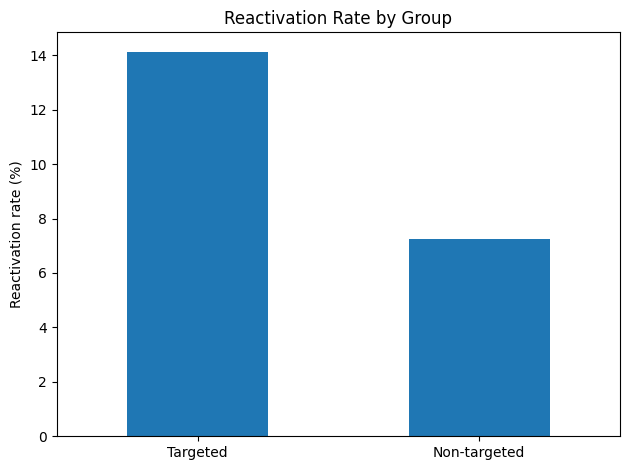

Absolute lift: 6.90 percentage points


In [5]:

rates = pd.Series({
    "Targeted": target_rate * 100,
    "Non-targeted": control_rate * 100
})

ax = rates.plot(kind="bar", rot=0)
ax.set_title("Reactivation Rate by Group")
ax.set_ylabel("Reactivation rate (%)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

print(
    f"Absolute lift: {absolute_lift * 100:.2f} percentage points"
)


In [6]:

def engagement_metrics(group, group_name):
    returned = group[group["reactivated"] == 1]

    return {
        "Group": group_name,
        "Eligible users": len(group),
        "Reactivated users": int(group["reactivated"].sum()),
        "D1 retention": returned["d1_retained"].mean(),
        "D7 retention": returned["d7_retained"].mean(),
        "Avg. sessions per returned user":
            returned["sessions_7d"].mean(),
        "Sessions per eligible user":
            group["sessions_7d"].sum() / len(group)
    }

engagement = pd.DataFrame([
    engagement_metrics(target, "Targeted"),
    engagement_metrics(control, "Non-targeted")
])

display(engagement.round(3))


,Group,Eligible users,Reactivated users,D1 retention,D7 retention,Avg. sessions per returned user,Sessions per eligible user
0,Targeted,4302,608,0.61,0.293,4.118,0.582
1,Non-targeted,5698,412,0.60,0.345,4.063,0.294


In [7]:

# Revenue and ad cost for targeted users
campaign_revenue = target["revenue_7d"].sum()
campaign_cost = target["ad_cost"].sum()

reactivated_count = target["reactivated"].sum()

# Attributed ROAS
roas = (
    campaign_revenue / campaign_cost
    if campaign_cost > 0 else np.nan
)

# Cost per reactivated user
cost_per_reactivated = (
    campaign_cost / reactivated_count
    if reactivated_count > 0 else np.nan
)

print("MONETIZATION RESULTS")
print("--------------------")
print(f"7-day revenue: ${campaign_revenue:,.2f}")
print(f"Ad cost: ${campaign_cost:,.2f}")
print(f"Attributed ROAS: {roas:.2f}x")
print(f"Cost per reactivated user: ${cost_per_reactivated:.2f}")


MONETIZATION RESULTS
--------------------
7-day revenue: $1,119.76
Ad cost: $933.97
Attributed ROAS: 1.20x
Cost per reactivated user: $1.54


In [9]:

print("FINAL CAMPAIGN SUMMARY")
print("======================")

print(f"Targeted users: {len(target):,}")
print(f"Reactivation rate: {target_rate:.2%}")
print(f"Control reactivation rate: {control_rate:.2%}")
print(f"Raw lift: {absolute_lift * 100:.2f} percentage points")
print(f"Attributed ROAS: {roas:.2f}x")




FINAL CAMPAIGN SUMMARY
Targeted users: 4,302
Reactivation rate: 14.13%
Control reactivation rate: 7.23%
Raw lift: 6.90 percentage points
Attributed ROAS: 1.20x
